In [119]:
import pandas as pd
import psycopg2
from psycopg2 import sql
import jinja2
import pdfkit
import numpy as np
import matplotlib.pyplot as plt
from pandas.plotting import table 

In [49]:
dbUser = "postgres"
dbPass = "postgresdocker#"
dbHost = "192.168.113.250"
dbPort = "5433"
dbName = "lnd"
pd.set_option('display.float_format', lambda x: '%.f' % x)
class PrepareReport:

	def __init__(self, lnd_node, start_date, end_date):
		self.lnd_node=lnd_node
		self.start_date = start_date
		self.end_date = end_date
		
	# connect to Postgres DB
	def connect_to_postgres(self):
		try:
			#connect to DB and return connection
			connection = psycopg2.connect(user = dbUser, password = dbPass, host=dbHost, port=dbPort, database = dbName)
			return connection
		except Exception as e:
			print("Exception {}".format(e))
			
	def get_forwarding_history_data(self):
		try:
			
			column_names = ["event_timestamp", "chan_id_in", "chan_id_out", "amt_in", "amt_out", "fee", "fee_msat", "amt_in_msat", "amt_out_msat", "timestamp_ns", "lnd_node"]
			sql = "SELECT event_timestamp, chan_id_in, chan_id_out, amt_in, amt_out, fee, fee_msat, amt_in_msat, amt_out_msat, timestamp_ns, lnd_node FROM forwarding_events WHERE lnd_node='{}';".format(self.lnd_node)
			
			# get connection and create cursor
			con = self.connect_to_postgres()
			cursor = con.cursor()

			cursor.execute(sql)
			rows = cursor.fetchall()
			df = pd.DataFrame(rows, columns=column_names)
			
			#get channel age dataframe
			sql_chan_age = "SELECT * FROM channel_age;"
			cursor.execute(sql_chan_age)
			rows_chan_age = cursor.fetchall()
			df_chan_age = pd.DataFrame(rows_chan_age, columns = ['chan_id', 'timestamp_ns'])

			con.close()
			return df, df_chan_age
		except Exception as e:
			print(f"Exception in get_forwarding_history_data: {e}")
			
#	def create_forwarding_history_report(self):
#		try:
#
#		except Exception as e:
#			print(f"Exception in create forwarding history report: {e}")
			

In [50]:
pr = PrepareReport("lnd-885", None, None)
df, df_chan_age = pr.get_forwarding_history_data()

In [51]:
df_total_events_out = df['chan_id_out'].value_counts().to_frame("total_events_out")
df_total_events_in = df['chan_id_in'].value_counts().to_frame("total_events_in")
print(df_total_events_out.sum(), df_total_events_in.sum())

total_events_out    518
dtype: int64 total_events_in    518
dtype: int64


In [52]:
sum(df['chan_id_out'].value_counts())

518

In [53]:
sum(df['chan_id_in'].value_counts())

518

- count df total events in and out and join them and total them
- count fees only on out 
- amount 

In [54]:
df_tmp = pd.concat([df_total_events_in, df_total_events_out]).fillna(0).reset_index()
df_tmp.columns = ['chan_id', 'total_events_in', 'total_events_out']
df_total_events = df_tmp.groupby(['chan_id']).agg({"total_events_in":"sum", "total_events_out":"sum"}).reset_index()

In [55]:
#get number of events
df_total_events['total_events'] = df_total_events['total_events_in'] + df_total_events['total_events_out']
df_total_events.columns = ['chan_id', 'total_events_in', 'total_events_out', 'total_events']

In [56]:
df_total_events.sum()

chan_id            4813599239355498496
total_events_in                    518
total_events_out                   518
total_events                      1036
dtype: float64

In [57]:
#get age of channels
today = pd.to_datetime("today")
df_chan_age['age_days'] = today - pd.to_datetime(df_chan_age['timestamp_ns'])
df_chan_age['age_days'] = df_chan_age['age_days'].dt.days

#make sure no age value is zero min 1 day
df_chan_age.loc[df_chan_age.age_days == 0, "age_days"] = 1

In [58]:
#get total amount in on chan_in
chan_in_df_total_amount = df.groupby('chan_id_in', as_index=False)['amt_in_msat'].sum()
chan_in_df_total_amount.columns = ['chan_id', 'amt_in']

In [59]:
#getting total fees, amount out for chan_id_out
chan_out_df_total_fees = df.groupby('chan_id_out', as_index=False)[['fee','fee_msat', 'amt_out_msat']].sum()
chan_out_df_total_fees['fee'] = chan_out_df_total_fees['fee_msat']/1000
chan_out_df_total_fees.rename(columns={'chan_id_out': 'chan_id', 'fee':'fee','fee_msat':'fee_msat', 'amt_out_msat':'amt_out'}, inplace=True)

In [60]:
chan_out_df_total_fees.merge(chan_in_df_total_amount, on='chan_id', how='outer').sum()

chan_id    4813599239355498496
fee                        637
fee_msat                636745
amt_out           118880009585
amt_in            118880646330
dtype: float64

In [61]:
df_tmp_amt = chan_out_df_total_fees.merge(chan_in_df_total_amount, how='outer').fillna(0)
chan_out_df_total_fees = df_tmp_amt.groupby(['chan_id']).agg({"fee":"sum", "fee_msat":"sum", "amt_in":"sum", "amt_out":"sum"}).reset_index()
chan_out_df_total_fees = chan_in_df_total_amount.merge(chan_out_df_total_fees, how='outer')

In [62]:
chan_out_df_total_fees.count()

chan_id     53
amt_in      53
fee         53
fee_msat    53
amt_out     53
dtype: int64

In [63]:
df_total_events.count()

chan_id             53
total_events_in     53
total_events_out    53
total_events        53
dtype: int64

In [64]:
df_chan_age.count()

chan_id         53
timestamp_ns    53
age_days        53
dtype: int64

In [65]:
#join df_chan_age with total events
df_chan_age_events = df_chan_age.merge(df_total_events, how='outer')

In [66]:
df_chan_age_events.count()

chan_id             53
timestamp_ns        53
age_days            53
total_events_in     53
total_events_out    53
total_events        53
dtype: int64

In [67]:
#join chan age and values df
df_chan_total_and_age = chan_out_df_total_fees.merge(df_chan_age_events, how='outer')

In [68]:
df_chan_total_and_age.count()

chan_id             53
amt_in              53
fee                 53
fee_msat            53
amt_out             53
timestamp_ns        53
age_days            53
total_events_in     53
total_events_out    53
total_events        53
dtype: int64

In [69]:
df_chan_total_and_age['avg_amt_in_per_event'] = df_chan_total_and_age['amt_in']/df_chan_total_and_age['total_events_in']
df_chan_total_and_age['avg_amt_out_per_event'] = df_chan_total_and_age['amt_out']/df_chan_total_and_age['total_events_out']
# df_chan_total_and_age.drop(columns=['timestamp_ns'], inplace=True)

In [70]:
df_chan_total_and_age

,chan_id,amt_in,fee,fee_msat,amt_out,timestamp_ns,age_days,total_events_in,total_events_out,total_events,avg_amt_in_per_event,avg_amt_out_per_event
0,781839628895059970,9838562963,68,67577,8592206645,1639267477727724755,36,123,59,182,79988317,145630621
1,781977067852595200,527431144,2,2400,400029600,1641007737540279520,16,4,2,6,131857786,200014800
2,784692861489315841,929079856,0,0,0,1639330286885873843,35,2,0,2,464539928,NaN
3,784917161945530368,5870366893,37,36975,4987009379,1639508921097773114,33,43,32,75,136520160,155844043
4,784967739478310912,3905449591,109,109291,5347377560,1639770990033535474,30,8,104,112,488181199,51417092
5,785219527543881728,303705863,7,6924,926482343,1639508921097773114,33,3,6,9,101235288,154413724
6,785220627059507200,684428302,2,2339,339817050,1640208726258086068,25,2,2,4,342214151,169908525
7,785253612476301312,250023658,5,4730,730921417,1640906646839333162,17,1,4,5,250023658,182730354
8,785255811538550785,967584572,0,0,0,1639751473649081565,30,3,0,3,322528191,NaN
9,785255811572039680,7576668466,14,13678,7680287099,1640208726258086068,25,40,6,46,189416712,1280047850


In [71]:
#calculate average values
#1 day fee average
df_chan_total_and_age['fee_msat_1d'] = df_chan_total_and_age['fee_msat']/df_chan_total_and_age['age_days']

#make 7d fee average
df_chan_total_and_age['fee_msat_7d'] = df_chan_total_and_age['fee_msat_1d']*7

#make 7d fee average
df_chan_total_and_age['fee_msat_30d'] = df_chan_total_and_age['fee_msat_1d']*30

In [72]:
df_chan_total_and_age

,chan_id,amt_in,fee,fee_msat,amt_out,timestamp_ns,age_days,total_events_in,total_events_out,total_events,avg_amt_in_per_event,avg_amt_out_per_event,fee_msat_1d,fee_msat_7d,fee_msat_30d
0,781839628895059970,9838562963,68,67577,8592206645,1639267477727724755,36,123,59,182,79988317,145630621,1877,13140,56314
1,781977067852595200,527431144,2,2400,400029600,1641007737540279520,16,4,2,6,131857786,200014800,150,1050,4500
2,784692861489315841,929079856,0,0,0,1639330286885873843,35,2,0,2,464539928,NaN,0,0,0
3,784917161945530368,5870366893,37,36975,4987009379,1639508921097773114,33,43,32,75,136520160,155844043,1120,7843,33614
4,784967739478310912,3905449591,109,109291,5347377560,1639770990033535474,30,8,104,112,488181199,51417092,3643,25501,109291
5,785219527543881728,303705863,7,6924,926482343,1639508921097773114,33,3,6,9,101235288,154413724,210,1469,6295
6,785220627059507200,684428302,2,2339,339817050,1640208726258086068,25,2,2,4,342214151,169908525,94,655,2807
7,785253612476301312,250023658,5,4730,730921417,1640906646839333162,17,1,4,5,250023658,182730354,278,1948,8347
8,785255811538550785,967584572,0,0,0,1639751473649081565,30,3,0,3,322528191,NaN,0,0,0
9,785255811572039680,7576668466,14,13678,7680287099,1640208726258086068,25,40,6,46,189416712,1280047850,547,3830,16414


In [73]:
#calculate average amount in values
#1 day fee average
df_chan_total_and_age['amt_in_1d'] = df_chan_total_and_age['amt_in']/df_chan_total_and_age['age_days']

#make 7d fee average
df_chan_total_and_age['amt_in_7d'] = df_chan_total_and_age['amt_in_1d']*7

#make 7d fee average
df_chan_total_and_age['amt_in_30d'] = df_chan_total_and_age['amt_in_1d']*30

In [74]:
df_chan_total_and_age

,chan_id,amt_in,fee,fee_msat,amt_out,timestamp_ns,age_days,total_events_in,total_events_out,total_events,avg_amt_in_per_event,avg_amt_out_per_event,fee_msat_1d,fee_msat_7d,fee_msat_30d,amt_in_1d,amt_in_7d,amt_in_30d
0,781839628895059970,9838562963,68,67577,8592206645,1639267477727724755,36,123,59,182,79988317,145630621,1877,13140,56314,273293416,1913053909,8198802469
1,781977067852595200,527431144,2,2400,400029600,1641007737540279520,16,4,2,6,131857786,200014800,150,1050,4500,32964446,230751126,988933395
2,784692861489315841,929079856,0,0,0,1639330286885873843,35,2,0,2,464539928,NaN,0,0,0,26545139,185815971,796354162
3,784917161945530368,5870366893,37,36975,4987009379,1639508921097773114,33,43,32,75,136520160,155844043,1120,7843,33614,177889906,1245229341,5336697175
4,784967739478310912,3905449591,109,109291,5347377560,1639770990033535474,30,8,104,112,488181199,51417092,3643,25501,109291,130181653,911271571,3905449591
5,785219527543881728,303705863,7,6924,926482343,1639508921097773114,33,3,6,9,101235288,154413724,210,1469,6295,9203208,64422456,276096239
6,785220627059507200,684428302,2,2339,339817050,1640208726258086068,25,2,2,4,342214151,169908525,94,655,2807,27377132,191639925,821313962
7,785253612476301312,250023658,5,4730,730921417,1640906646839333162,17,1,4,5,250023658,182730354,278,1948,8347,14707274,102950918,441218220
8,785255811538550785,967584572,0,0,0,1639751473649081565,30,3,0,3,322528191,NaN,0,0,0,32252819,225769733,967584572
9,785255811572039680,7576668466,14,13678,7680287099,1640208726258086068,25,40,6,46,189416712,1280047850,547,3830,16414,303066739,2121467170,9092002159


In [75]:
#calculate average amount out values
#1 day fee average
df_chan_total_and_age['amt_out_1d'] = df_chan_total_and_age['amt_out']/df_chan_total_and_age['age_days']

#make 7d fee average
df_chan_total_and_age['amt_out_7d'] = df_chan_total_and_age['amt_out_1d']*7

#make 7d fee average
df_chan_total_and_age['amt_out_30d'] = df_chan_total_and_age['amt_out_1d']*30

In [76]:
df_chan_total_and_age

,chan_id,amt_in,fee,fee_msat,amt_out,timestamp_ns,age_days,total_events_in,total_events_out,total_events,...,avg_amt_out_per_event,fee_msat_1d,fee_msat_7d,fee_msat_30d,amt_in_1d,amt_in_7d,amt_in_30d,amt_out_1d,amt_out_7d,amt_out_30d
0,781839628895059970,9838562963,68,67577,8592206645,1639267477727724755,36,123,59,182,...,145630621,1877,13140,56314,273293416,1913053909,8198802469,238672407,1670706848,7160172204
1,781977067852595200,527431144,2,2400,400029600,1641007737540279520,16,4,2,6,...,200014800,150,1050,4500,32964446,230751126,988933395,25001850,175012950,750055500
2,784692861489315841,929079856,0,0,0,1639330286885873843,35,2,0,2,...,NaN,0,0,0,26545139,185815971,796354162,0,0,0
3,784917161945530368,5870366893,37,36975,4987009379,1639508921097773114,33,43,32,75,...,155844043,1120,7843,33614,177889906,1245229341,5336697175,151121496,1057850474,4533644890
4,784967739478310912,3905449591,109,109291,5347377560,1639770990033535474,30,8,104,112,...,51417092,3643,25501,109291,130181653,911271571,3905449591,178245919,1247721431,5347377560
5,785219527543881728,303705863,7,6924,926482343,1639508921097773114,33,3,6,9,...,154413724,210,1469,6295,9203208,64422456,276096239,28075223,196526558,842256675
6,785220627059507200,684428302,2,2339,339817050,1640208726258086068,25,2,2,4,...,169908525,94,655,2807,27377132,191639925,821313962,13592682,95148774,407780460
7,785253612476301312,250023658,5,4730,730921417,1640906646839333162,17,1,4,5,...,182730354,278,1948,8347,14707274,102950918,441218220,42995377,300967642,1289861324
8,785255811538550785,967584572,0,0,0,1639751473649081565,30,3,0,3,...,NaN,0,0,0,32252819,225769733,967584572,0,0,0
9,785255811572039680,7576668466,14,13678,7680287099,1640208726258086068,25,40,6,46,...,1280047850,547,3830,16414,303066739,2121467170,9092002159,307211484,2150480388,9216344519


In [77]:
df_chan_total_and_age.loc[df_chan_total_and_age['age_days'] < 30, ["amt_out_30d", "amt_in_30d", "fee_msat_30d"]]=None
df_chan_total_and_age.loc[df_chan_total_and_age['age_days'] < 7, ["amt_out_7d", "amt_in_7d", "fee_msat_7d"]]=None

In [78]:
df_chan_total_and_age

,chan_id,amt_in,fee,fee_msat,amt_out,timestamp_ns,age_days,total_events_in,total_events_out,total_events,...,avg_amt_out_per_event,fee_msat_1d,fee_msat_7d,fee_msat_30d,amt_in_1d,amt_in_7d,amt_in_30d,amt_out_1d,amt_out_7d,amt_out_30d
0,781839628895059970,9838562963,68,67577,8592206645,1639267477727724755,36,123,59,182,...,145630621,1877,13140,56314,273293416,1913053909,8198802469,238672407,1670706848,7160172204
1,781977067852595200,527431144,2,2400,400029600,1641007737540279520,16,4,2,6,...,200014800,150,1050,NaN,32964446,230751126,NaN,25001850,175012950,NaN
2,784692861489315841,929079856,0,0,0,1639330286885873843,35,2,0,2,...,NaN,0,0,0,26545139,185815971,796354162,0,0,0
3,784917161945530368,5870366893,37,36975,4987009379,1639508921097773114,33,43,32,75,...,155844043,1120,7843,33614,177889906,1245229341,5336697175,151121496,1057850474,4533644890
4,784967739478310912,3905449591,109,109291,5347377560,1639770990033535474,30,8,104,112,...,51417092,3643,25501,109291,130181653,911271571,3905449591,178245919,1247721431,5347377560
5,785219527543881728,303705863,7,6924,926482343,1639508921097773114,33,3,6,9,...,154413724,210,1469,6295,9203208,64422456,276096239,28075223,196526558,842256675
6,785220627059507200,684428302,2,2339,339817050,1640208726258086068,25,2,2,4,...,169908525,94,655,NaN,27377132,191639925,NaN,13592682,95148774,NaN
7,785253612476301312,250023658,5,4730,730921417,1640906646839333162,17,1,4,5,...,182730354,278,1948,NaN,14707274,102950918,NaN,42995377,300967642,NaN
8,785255811538550785,967584572,0,0,0,1639751473649081565,30,3,0,3,...,NaN,0,0,0,32252819,225769733,967584572,0,0,0
9,785255811572039680,7576668466,14,13678,7680287099,1640208726258086068,25,40,6,46,...,1280047850,547,3830,NaN,303066739,2121467170,NaN,307211484,2150480388,NaN


In [79]:
df_chan_total_and_age.sort_values(by="total_events", ascending=False, inplace=True)


In [80]:
df_chan_total_and_age

,chan_id,amt_in,fee,fee_msat,amt_out,timestamp_ns,age_days,total_events_in,total_events_out,total_events,...,avg_amt_out_per_event,fee_msat_1d,fee_msat_7d,fee_msat_30d,amt_in_1d,amt_in_7d,amt_in_30d,amt_out_1d,amt_out_7d,amt_out_30d
0,781839628895059970,9838562963,68,67577,8592206645,1639267477727724755,36,123,59,182,...,145630621,1877,13140,56314,273293416,1913053909,8198802469,238672407,1670706848,7160172204
4,784967739478310912,3905449591,109,109291,5347377560,1639770990033535474,30,8,104,112,...,51417092,3643,25501,109291,130181653,911271571,3905449591,178245919,1247721431,5347377560
28,788468584512684033,3353403988,70,70088,3090252254,1641341980273804801,12,10,67,77,...,46123168,5841,40885,NaN,279450332,1956152326,NaN,257521021,1802647148,NaN
3,784917161945530368,5870366893,37,36975,4987009379,1639508921097773114,33,43,32,75,...,155844043,1120,7843,33614,177889906,1245229341,5336697175,151121496,1057850474,4533644890
15,786504856754192385,7264904071,43,42823,6826709399,1640280974254443474,24,22,36,58,...,189630817,1784,12490,NaN,302704336,2118930354,NaN,284446225,1991123575,NaN
24,787772593542725632,11435496881,41,40764,8770606139,1640945906090934254,17,22,32,54,...,274081442,2398,16785,NaN,672676287,4708734010,NaN,515918008,3611426057,NaN
9,785255811572039680,7576668466,14,13678,7680287099,1640208726258086068,25,40,6,46,...,1280047850,547,3830,NaN,303066739,2121467170,NaN,307211484,2150480388,NaN
20,786800625295818752,4628084061,31,30525,12530659032,1640379225573275430,23,22,18,40,...,696147724,1327,9290,NaN,201221046,1408547323,NaN,544811262,3813678836,NaN
25,787837464750260224,1998325131,10,10180,1180205739,1640960323483577358,16,24,9,33,...,131133971,636,4454,NaN,124895321,874267245,NaN,73762859,516340011,NaN
33,789077713898700800,2535671723,22,21574,3579492303,1641640826129125925,9,13,18,31,...,198860684,2397,16780,NaN,281741303,1972189118,NaN,397721367,2784049569,NaN


In [81]:
# df_chan_total_and_age['chan_id'] = df_chan_total_and_age['chan_id'].astype('float64')

In [82]:
df_chan_total_and_age.fillna(0, inplace=True)
# df_chan_total_and_age.reset_index(inplace=True)

In [83]:
df_tmp = pd.DataFrame(df_chan_total_and_age.sum(numeric_only=True)[1:]).T.reset_index()

In [84]:
final_df = df_chan_total_and_age.set_index('chan_id').append(df_tmp).reset_index()
final_df = final_df.rename(columns={'level_0':'chan_id'})

In [ ]:
final_df.iloc[-1, final_df.columns.get_loc('chan_id')] = "Total"

In [ ]:
final_df.drop(columns=['index'], inplace=True)

In [ ]:
delta_days = pd.to_datetime("01-01-2022")- pd.to_datetime("12-13-2021")
final_df['age_days_tmp'] = final_df['age_days']
final_df.loc[final_df['age_days'] > delta_days.days, ['age_days_tmp']] = delta_days.days

In [ ]:
delta_days.days

In [102]:
df_chan_total_and_age['date'] = pd.to_datetime(df_chan_total_and_age['timestamp_ns'])

In [123]:
day_of_week_df = df_chan_total_and_age.groupby(df_chan_total_and_age['date'].dt.day_name())[['total_events_in', 'total_events_out', 'total_events']].sum().sort_values(by='total_events', ascending=False)

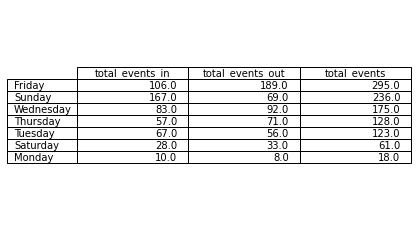

<Figure size 432x288 with 0 Axes>

In [126]:
ax = plt.subplot(111, frame_on=False) # no visible frame
ax.xaxis.set_visible(False)  # hide the x axis
ax.yaxis.set_visible(False)  # hide the y axis

table(ax, day_of_week_df, loc='center')  # where df is your data frame
plt.show()
plt.savefig('mytable.png')